In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt

In [2]:
ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

# Replace with the exact attached file path.
MANIFEST_PATH = Path(
    "/kaggle/input/datasets/zidanefatuna/"
    "dataset-manifest-seed42-csv/dataset_manifest_seed42.csv"
)

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str,
    },
)

assert len(manifest) == 174
assert manifest["StudyInstanceUID"].nunique() == 58
assert not manifest.duplicated(
    ["StudyInstanceUID", "Anatomical_Plane"]
).any()

print("Selected series:", len(manifest))
print("Studies:", manifest["StudyInstanceUID"].nunique())

display(pd.crosstab(
    manifest["split"],
    manifest["Anatomical_Plane"],
))

Selected series: 174
Studies: 58


Anatomical_Plane,Axial,Coronal,Sagittal
split,,,
train,46,46,46
validation,12,12,12


In [3]:
# Start with a smaller sagittal training series.
example = (
    manifest.loc[
        manifest["split"].eq("train")
        & manifest["Anatomical_Plane"].eq("Sagittal")
    ]
    .sort_values(["file_count", "SeriesInstanceUID"])
    .iloc[0]
)

series_folder = ROOT / example["series_relative_path"]
dicom_files = sorted(series_folder.glob("*.dcm"))

if len(dicom_files) != int(example["file_count"]):
    raise ValueError("File count differs from the saved manifest.")

headers = [
    pydicom.dcmread(path, stop_before_pixels=True)
    for path in dicom_files
]

orientations = np.asarray(
    [ds.ImageOrientationPatient for ds in headers],
    dtype=float,
)
positions = np.asarray(
    [ds.ImagePositionPatient for ds in headers],
    dtype=float,
)

if not np.allclose(
    orientations, orientations[0], atol=1e-4, rtol=0
):
    raise ValueError("Slice orientations differ.")

normal = np.cross(orientations[0, :3], orientations[0, 3:])
normal /= np.linalg.norm(normal)

projected_positions = positions @ normal
order = np.argsort(projected_positions)

ordered_files = [dicom_files[i] for i in order]
ordered_headers = [headers[i] for i in order]
slice_spacing = np.diff(projected_positions[order])

print("Description:", getattr(headers[0], "SeriesDescription", "Missing"))
print("Ordered files:", len(ordered_files))
print("Rows × columns:", headers[0].Rows, "×", headers[0].Columns)
print("Pixel spacing (mm):", headers[0].PixelSpacing)
print("Median slice spacing (mm):", round(float(np.median(slice_spacing)), 4))
print(
    "Photometric interpretations:",
    sorted({str(ds.PhotometricInterpretation) for ds in headers}),
)
print(
    "Slices with a modality LUT:",
    sum("ModalityLUTSequence" in ds for ds in headers),
)

Description: Sag T2 FS
Ordered files: 19
Rows × columns: 512 × 512
Pixel spacing (mm): [0.3906, 0.3906]
Median slice spacing (mm): 4.4
Photometric interpretations: ['MONOCHROME2']
Slices with a modality LUT: 0


In [4]:
slices = []
scaling_records = []

for path in ordered_files:
    ds = pydicom.dcmread(path)

    if "ModalityLUTSequence" in ds:
        raise ValueError("This reader does not yet handle modality LUTs.")

    pixels = ds.pixel_array

    if pixels.ndim != 2:
        raise ValueError(f"Expected a 2D slice, got {pixels.shape}")

    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))

    scaled = pixels.astype(np.float32) * slope + intercept
    slices.append(scaled)

    scaling_records.append({
        "slope": slope,
        "intercept": intercept,
    })

volume = np.stack(slices, axis=0)

assert np.isfinite(volume).all()

print("Volume shape:", volume.shape)
print("Data type:", volume.dtype)
print("Scaled intensity range:", volume.min(), "to", volume.max())

display(
    pd.DataFrame(scaling_records)
    .value_counts()
    .reset_index(name="slice_count")
)

Volume shape: (19, 512, 512)
Data type: float32
Scaled intensity range: 0.0 to 2273.0


,slope,intercept,slice_count
0,1.0,0.0,19


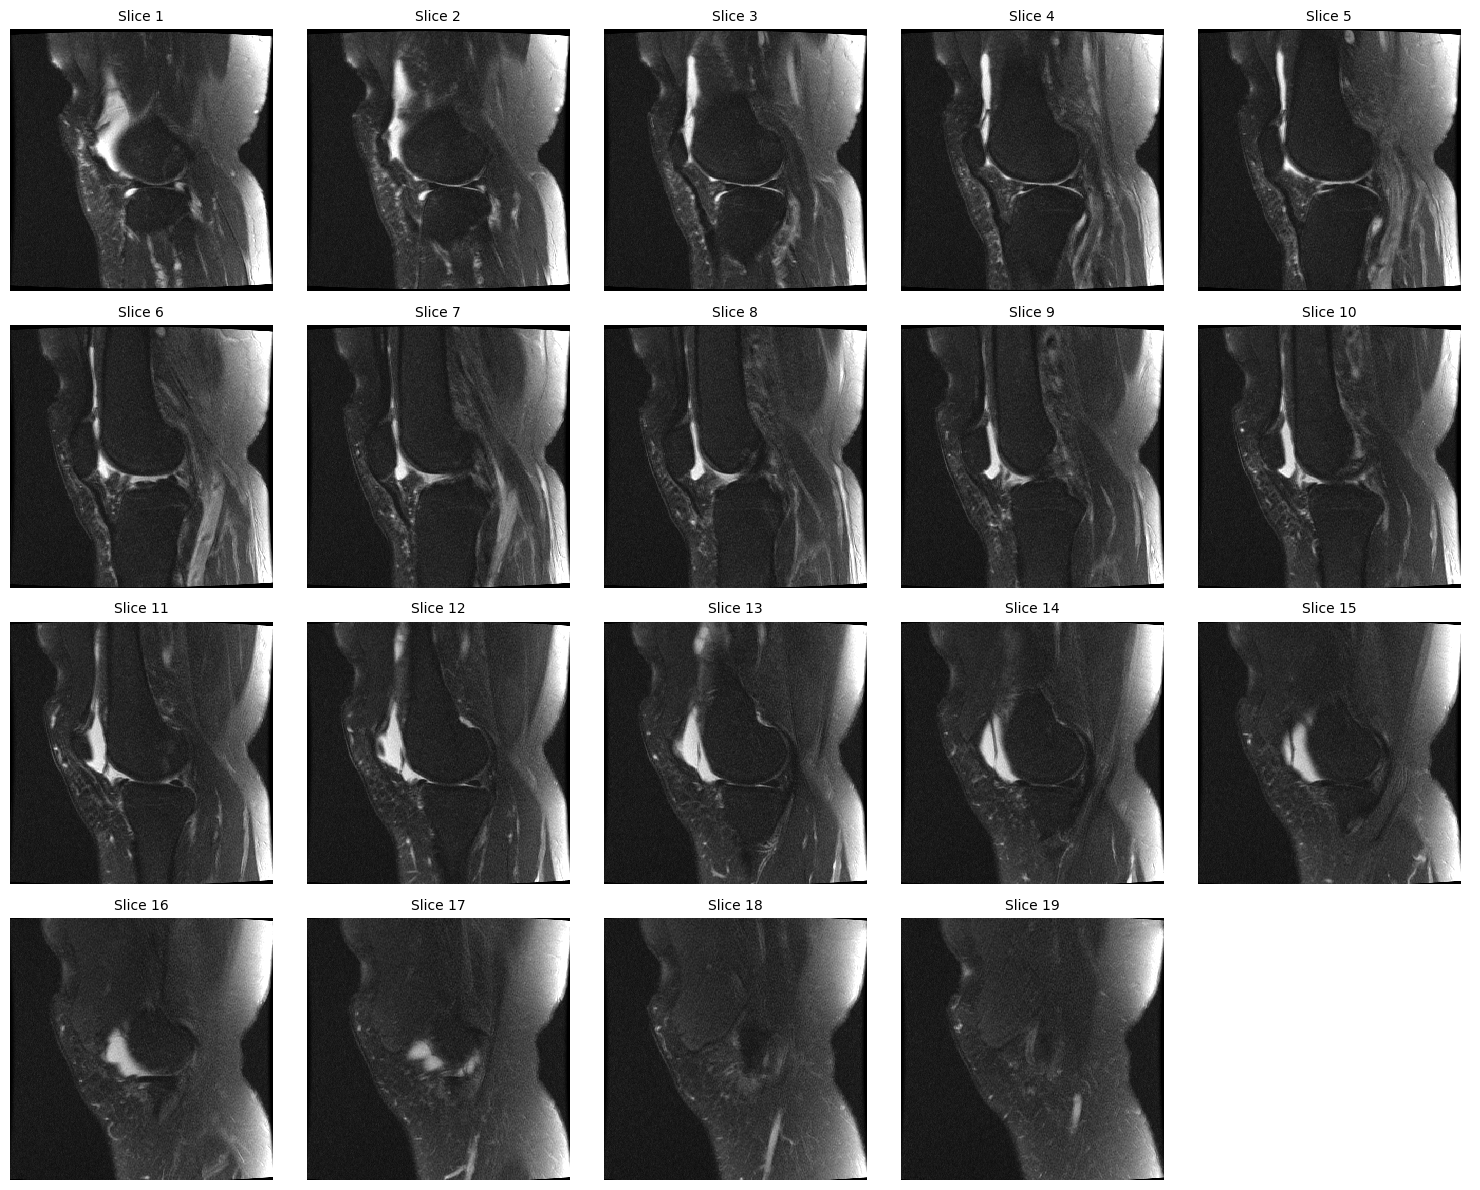

Display limits: 0.0 to 1388.0


In [5]:
# Shared display limits across the entire volume.
vmin, vmax = np.percentile(volume, [1, 99])

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for i, ax in enumerate(axes.ravel()):
    if i < len(volume):
        ax.imshow(
            volume[i],
            cmap="gray",
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
        )
        ax.set_title(f"Slice {i + 1}", fontsize=10)

    ax.axis("off")

plt.tight_layout()
plt.show()

print("Display limits:", vmin, "to", vmax)

In [6]:
lower, upper = np.percentile(volume, [1, 99])

if upper <= lower:
    raise ValueError("Invalid intensity range for normalization.")

volume_normalized = (
    (np.clip(volume, lower, upper) - lower)
    / (upper - lower)
).astype(np.float32)

print("Clipping thresholds:", lower, upper)
print("Shape:", volume_normalized.shape)
print("Data type:", volume_normalized.dtype)
print("Range:", volume_normalized.min(), volume_normalized.max())
print("All finite:", np.isfinite(volume_normalized).all())

Clipping thresholds: 0.0 1388.0
Shape: (19, 512, 512)
Data type: float32
Range: 0.0 1.0
All finite: True


In [7]:
import cv2

volume_resized = np.stack([
    cv2.resize(
        image,
        (224, 224),  # OpenCV uses (width, height).
        interpolation=cv2.INTER_AREA,
    )
    for image in volume_normalized
]).astype(np.float32)

print("Resized shape:", volume_resized.shape)
print("Data type:", volume_resized.dtype)
print("Range:", volume_resized.min(), volume_resized.max())
print("All finite:", np.isfinite(volume_resized).all())

Resized shape: (19, 224, 224)
Data type: float32
Range: 0.0 1.0
All finite: True


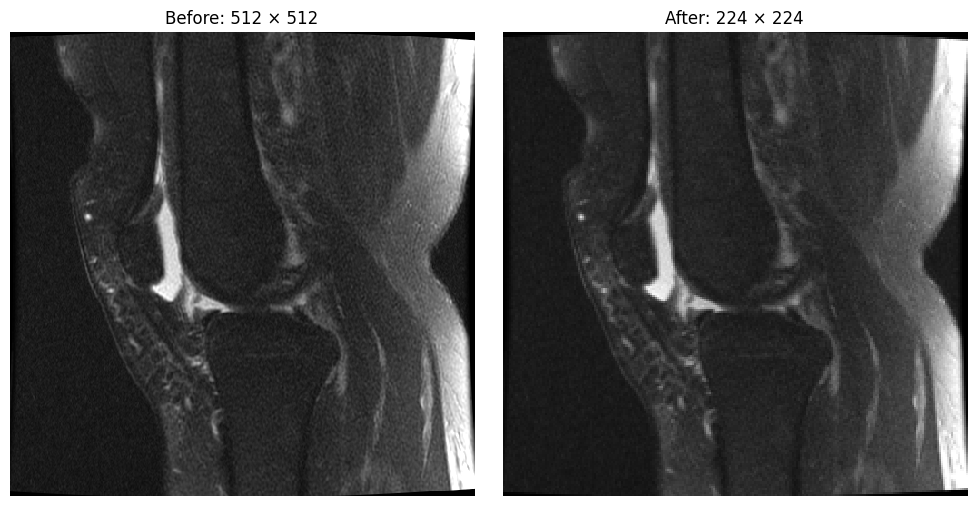

In [8]:
slice_index = len(volume_normalized) // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, data, title in zip(
    axes,
    [volume_normalized, volume_resized],
    ["Before: 512 × 512", "After: 224 × 224"],
):
    ax.imshow(
        data[slice_index],
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import cv2
from tqdm.auto import tqdm

OUTPUT_DIR = Path("/kaggle/working/preprocessed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def preprocess_series(row):
    folder = ROOT / row["series_relative_path"]
    files = sorted(folder.glob("*.dcm"))

    if len(files) != int(row["file_count"]) or len(files) < 2:
        raise ValueError("Unexpected DICOM file count")

    headers = [
        pydicom.dcmread(path, stop_before_pixels=True)
        for path in files
    ]

    for ds in headers:
        if str(ds.StudyInstanceUID) != row["StudyInstanceUID"]:
            raise ValueError("Study UID mismatch")
        if str(ds.SeriesInstanceUID) != row["SeriesInstanceUID"]:
            raise ValueError("Series UID mismatch")
        if int(getattr(ds, "NumberOfFrames", 1)) != 1:
            raise ValueError("Multi-frame DICOM requires review")
        if ds.PhotometricInterpretation != "MONOCHROME2":
            raise ValueError("Non-MONOCHROME2 image requires review")
        if "ModalityLUTSequence" in ds:
            raise ValueError("Modality LUT requires separate handling")
        if "PixelPaddingValue" in ds:
            raise ValueError("Pixel padding requires masking before percentiles")

    orientations = np.asarray(
        [ds.ImageOrientationPatient for ds in headers], dtype=float
    )
    positions = np.asarray(
        [ds.ImagePositionPatient for ds in headers], dtype=float
    )
    spacings = np.asarray(
        [ds.PixelSpacing for ds in headers], dtype=float
    )

    if not all(np.isfinite(a).all()
               for a in [orientations, positions, spacings]):
        raise ValueError("Non-finite geometry")

    if not np.allclose(orientations, orientations[0], atol=1e-4, rtol=0):
        raise ValueError("Varying orientation")
    if not np.allclose(spacings, spacings[0], atol=1e-5, rtol=1e-4):
        raise ValueError("Varying pixel spacing")
    if (spacings <= 0).any():
        raise ValueError("Invalid pixel spacing")

    dimensions = {(int(ds.Rows), int(ds.Columns)) for ds in headers}
    if len(dimensions) != 1:
        raise ValueError("Varying image dimensions")

    normal = np.cross(orientations[0, :3], orientations[0, 3:])
    normal_length = np.linalg.norm(normal)
    if normal_length < 1e-6:
        raise ValueError("Invalid slice normal")
    normal /= normal_length

    projected = positions @ normal
    order = np.argsort(projected)
    gaps = np.diff(projected[order])

    if (gaps < 0.001).any():
        raise ValueError("Duplicate or near-duplicate positions")
    if not np.allclose(gaps, np.median(gaps), atol=0.01, rtol=0.01):
        raise ValueError("Irregular slice spacing")

    height, width = next(iter(dimensions))
    volume = np.empty((len(files), height, width), dtype=np.float32)

    for output_index, file_index in enumerate(order):
        ds = pydicom.dcmread(files[file_index])
        pixels = ds.pixel_array

        if pixels.shape != (height, width):
            raise ValueError("Unexpected pixel-array shape")

        slope = float(getattr(ds, "RescaleSlope", 1))
        intercept = float(getattr(ds, "RescaleIntercept", 0))
        volume[output_index] = (
            pixels.astype(np.float32) * slope + intercept
        )

    if not np.isfinite(volume).all():
        raise ValueError("Non-finite pixel values")

    lower, upper = np.percentile(volume, [1, 99])
    if upper <= lower:
        raise ValueError("Degenerate intensity range")

    # Normalize in place to reduce peak memory usage.
    np.clip(volume, lower, upper, out=volume)
    volume -= lower
    volume /= upper - lower

    # Fit the physical field of view into a 224 × 224 canvas.
    row_mm, col_mm = spacings[0]
    fit_scale = min(
        224 / (height * row_mm),
        224 / (width * col_mm),
    )
    new_height = max(1, min(224, round(height * row_mm * fit_scale)))
    new_width = max(1, min(224, round(width * col_mm * fit_scale)))

    top = (224 - new_height) // 2
    left = (224 - new_width) // 2

    output = np.zeros((len(files), 224, 224), dtype=np.float32)
    interpolation = (
        cv2.INTER_AREA
        if new_height <= height and new_width <= width
        else cv2.INTER_LINEAR
    )

    for i, image in enumerate(volume):
        output[i, top:top + new_height, left:left + new_width] = (
            cv2.resize(
                image,
                (new_width, new_height),
                interpolation=interpolation,
            )
        )

    if not np.isfinite(output).all():
        raise ValueError("Non-finite processed output")

    metadata = {
        "original_rows": height,
        "original_columns": width,
        "slice_count": len(files),
        "clip_lower": float(lower),
        "clip_upper": float(upper),
        "content_height": new_height,
        "content_width": new_width,
        "pad_top": top,
        "pad_left": left,
        "source_row_spacing_mm": float(row_mm),
        "source_column_spacing_mm": float(col_mm),
        "resized_row_spacing_mm": float(height * row_mm / new_height),
        "resized_column_spacing_mm": float(width * col_mm / new_width),
    }

    return output, metadata

In [10]:
batch_records = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Preprocessing series",
):
    record = row.to_dict()
    record.update({
        "status": "failed",
        "error": "",
        "processed_relative_path": "",
    })

    try:
        processed, metadata = preprocess_series(row)

        relative_path = (
            Path(row["StudyInstanceUID"])
            / f"{row['SeriesInstanceUID']}.npy"
        )
        output_path = OUTPUT_DIR / relative_path
        output_path.parent.mkdir(parents=True, exist_ok=True)

        # Write to a temporary file, then rename after saving completes.
        temporary_path = output_path.with_suffix(".tmp")
        with temporary_path.open("wb") as handle:
            np.save(handle, processed, allow_pickle=False)
        temporary_path.replace(output_path)

        record.update(metadata)
        record["processed_relative_path"] = relative_path.as_posix()
        record["status"] = "ok"

        del processed

    except Exception as error:
        record["error"] = f"{type(error).__name__}: {error}"

    batch_records.append(record)

    pd.DataFrame(batch_records).to_csv(
        OUTPUT_DIR / "processed_manifest.csv",
        index=False,
    )

batch_log = pd.DataFrame(batch_records)

print(batch_log["status"].value_counts())
display(
    batch_log.loc[
        batch_log["status"].ne("ok"),
        ["StudyInstanceUID", "Anatomical_Plane", "error"],
    ]
)

Preprocessing series:   0%|          | 0/174 [00:00<?, ?it/s]

status
ok    174
Name: count, dtype: int64


,StudyInstanceUID,Anatomical_Plane,error


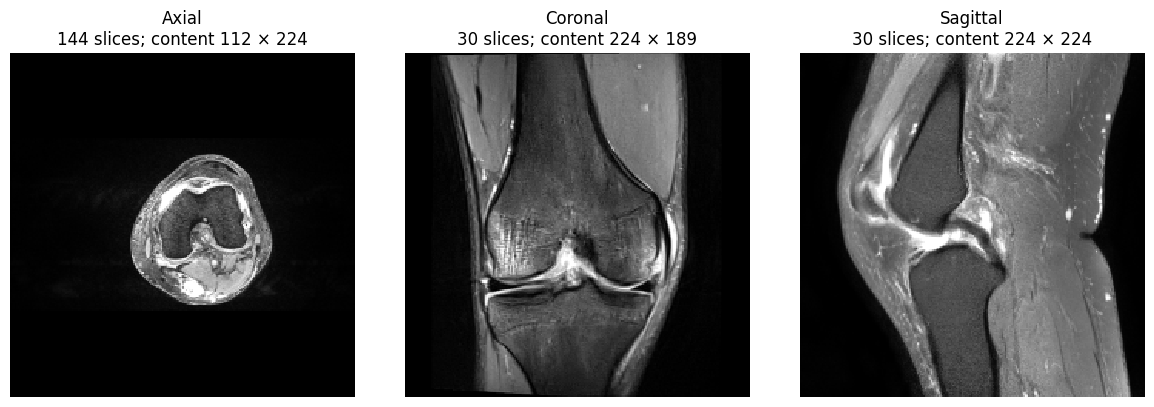

In [11]:
preview_rows = (
    batch_log.assign(
        content_area=batch_log["content_height"]
        * batch_log["content_width"]
    )
    .sort_values(["content_area", "SeriesInstanceUID"])
    .drop_duplicates("Anatomical_Plane")
)

fig, axes = plt.subplots(1, len(preview_rows), figsize=(12, 4))
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, preview_rows.iterrows()):
    array = np.load(
        OUTPUT_DIR / row["processed_relative_path"],
        allow_pickle=False,
    )

    ax.imshow(
        array[len(array) // 2],
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(
        f"{row['Anatomical_Plane']}\n"
        f"{len(array)} slices; content "
        f"{int(row['content_height'])} × {int(row['content_width'])}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import shutil

archive_path = shutil.make_archive(
    "/kaggle/working/rsna_preprocessed_seed42",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Archive saved:", archive_path)

Archive saved: /kaggle/working/rsna_preprocessed_seed42.zip


## Conclusions

- All 174 selected series from 58 labelled studies were processed:
  138 training series and 36 validation series.

- Slices were ordered using their physical positions and orientations.
  Rescale slope and intercept were applied separately to each slice.

- Intensities were clipped at each volume's 1st and 99th percentiles,
  then normalized to [0, 1]. These remain baseline preprocessing choices.

- Each slice was resized to fit a 224 × 224 canvas using its physical
  proportions, with zero padding where needed. Resizing reduces fine detail.

- Original slice counts were retained. Outputs have shape
  (number_of_slices, 224, 224) and dtype float32.

- All saved arrays passed shape, dtype, finite-value, and intensity-range
  checks. Selected previews showed the expected resizing and padding;
  this does not establish image quality across every slice.

- Physical spacing was not standardized across studies, and images were
  not reoriented into a common anatomical coordinate system.
  The saved arrays are model inputs, not complete spatial image records.

- No random augmentation was applied. Training augmentation will be
  performed when loading examples.

- processed_manifest.csv preserves the series paths, labels, study splits,
  preprocessing measurements, and processing status.